In [2]:
import pandas as pd, numpy as np

df = pd.read_csv('station_day.csv')
print(df.shape)
df.head()


(108035, 16)


,StationId,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,AP001,2017-11-24,71.36,115.75,1.75,20.65,12.40,12.19,0.10,10.76,109.26,0.17,5.92,0.10,NaN,NaN
1,AP001,2017-11-25,81.40,124.50,1.44,20.50,12.08,10.72,0.12,15.24,127.09,0.20,6.50,0.06,184.0,Moderate
2,AP001,2017-11-26,78.32,129.06,1.26,26.00,14.85,10.28,0.14,26.96,117.44,0.22,7.95,0.08,197.0,Moderate
3,AP001,2017-11-27,88.76,135.32,6.60,30.85,21.77,12.91,0.11,33.59,111.81,0.29,7.63,0.12,198.0,Moderate
4,AP001,2017-11-28,64.18,104.09,2.56,28.07,17.01,11.42,0.09,19.00,138.18,0.17,5.02,0.07,188.0,Moderate


In [3]:
df.info()
(df.isna().mean()*100).round(1).sort_values(ascending=False)


<class 'pandas.DataFrame'>
RangeIndex: 108035 entries, 0 to 108034
Data columns (total 16 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   StationId   108035 non-null  str    
 1   Date        108035 non-null  str    
 2   PM2.5       86410 non-null   float64
 3   PM10        65329 non-null   float64
 4   NO          90929 non-null   float64
 5   NO2         91488 non-null   float64
 6   NOx         92535 non-null   float64
 7   NH3         59930 non-null   float64
 8   CO          95037 non-null   float64
 9   SO2         82831 non-null   float64
 10  O3          82467 non-null   float64
 11  Benzene     76580 non-null   float64
 12  Toluene     69333 non-null   float64
 13  Xylene      22898 non-null   float64
 14  AQI         87025 non-null   float64
 15  AQI_Bucket  87025 non-null   str    
dtypes: float64(13), str(3)
memory usage: 13.2 MB


Xylene        78.8
NH3           44.5
PM10          39.5
Toluene       35.8
Benzene       29.1
O3            23.7
SO2           23.3
PM2.5         20.0
AQI_Bucket    19.4
AQI           19.4
NO            15.8
NO2           15.3
NOx           14.3
CO            12.0
Date           0.0
StationId      0.0
dtype: float64

In [8]:
import pandas as pd, numpy as np

df = pd.read_csv('station_day.csv')   # original file ka sahi path

In [10]:
# 1. Date features
try:
    df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
except ValueError:
    df['Date'] = pd.to_datetime(df['Date'], format='ISO8601')

df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

In [11]:
# 1. Date features
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

def season(m):
    return ('Winter' if m in (12,1,2) else 'Summer' if m in (3,4,5)
            else 'Monsoon' if m in (6,7,8,9) else 'Post-Monsoon')

df['Season'] = df['Month'].map(season)
df['State'] = df['StationId'].str[:2]   # AP001 -> AP

# 2. Drop Xylene and empty rows
df = df.drop(columns=['Xylene'])
pollutants = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3','Benzene','Toluene']
df = df.dropna(subset=pollutants, how='all')

# 3. Fill missing values (station median, then overall median)
df = df.sort_values(['StationId','Date'])
for c in pollutants:
    df[c] = df[c].fillna(df.groupby('StationId')[c].transform('median'))
    df[c] = df[c].fillna(df[c].median())

# 4. Fix AQI and rebuild bucket
df['AQI'] = df['AQI'].clip(upper=500)

def bucket(a):
    if pd.isna(a): return np.nan
    return ('Good' if a<=50 else 'Satisfactory' if a<=100 else 'Moderate' if a<=200
            else 'Poor' if a<=300 else 'Very Poor' if a<=400 else 'Severe')

df['AQI_Bucket'] = df['AQI'].map(bucket)
df = df.dropna(subset=['AQI'])

# 5. Cap outliers
for c in pollutants:
    df[c] = df[c].clip(upper=df[c].quantile(0.995))

df = df.reset_index(drop=True)
print('Clean shape:', df.shape)
df.to_csv('station_day_clean.csv', index=False)


Clean shape: (86754, 19)


In [12]:
df.isna().sum()

StationId     0
Date          0
PM2.5         0
PM10          0
NO            0
NO2           0
NOx           0
NH3           0
CO            0
SO2           0
O3            0
Benzene       0
Toluene       0
AQI           0
AQI_Bucket    0
Year          0
Month         0
Season        0
State         0
dtype: int64

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

df = pd.read_csv('station_day_clean.csv', parse_dates=['Date'])


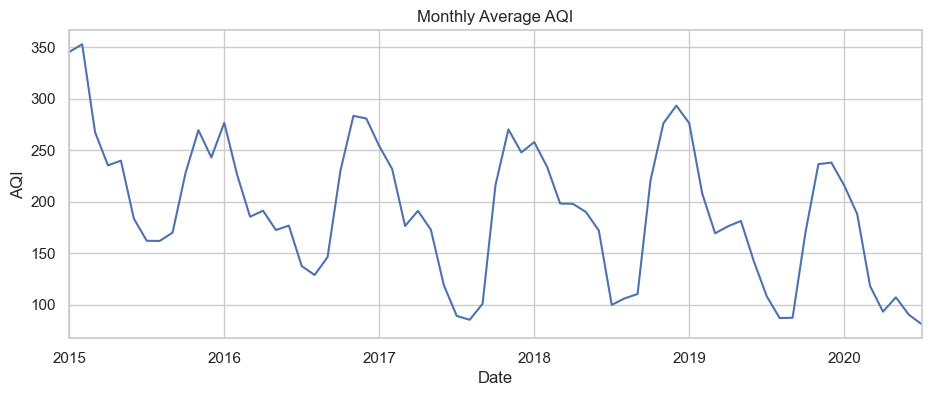

In [14]:
monthly = df.set_index('Date')['AQI'].resample('MS').mean()
plt.figure(figsize=(11,4))
monthly.plot()
plt.title('Monthly Average AQI'); plt.ylabel('AQI')
plt.show()


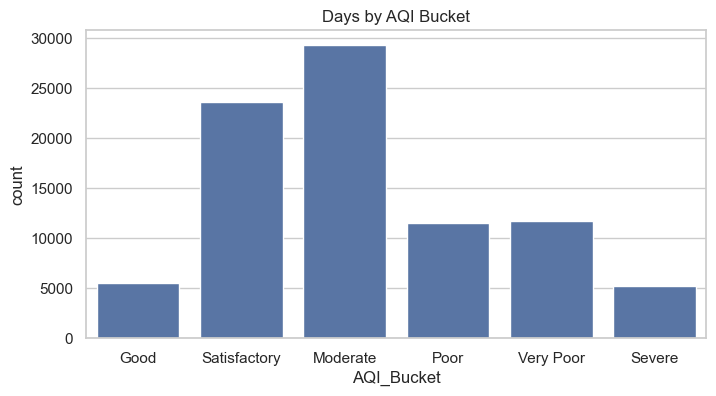

AQI_Bucket
Moderate        33.8
Satisfactory    27.2
Very Poor       13.5
Poor            13.2
Good             6.3
Severe           6.0
Name: proportion, dtype: float64

In [15]:
order = ['Good','Satisfactory','Moderate','Poor','Very Poor','Severe']
plt.figure(figsize=(8,4))
sns.countplot(data=df, x='AQI_Bucket', order=order)
plt.title('Days by AQI Bucket')
plt.show()
df['AQI_Bucket'].value_counts(normalize=True).mul(100).round(1)


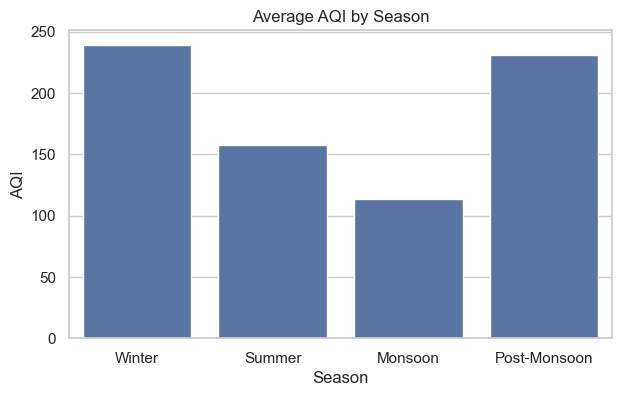

In [16]:
plt.figure(figsize=(7,4))
sns.barplot(data=df, x='Season', y='AQI',
            order=['Winter','Summer','Monsoon','Post-Monsoon'], errorbar=None)
plt.title('Average AQI by Season')
plt.show()


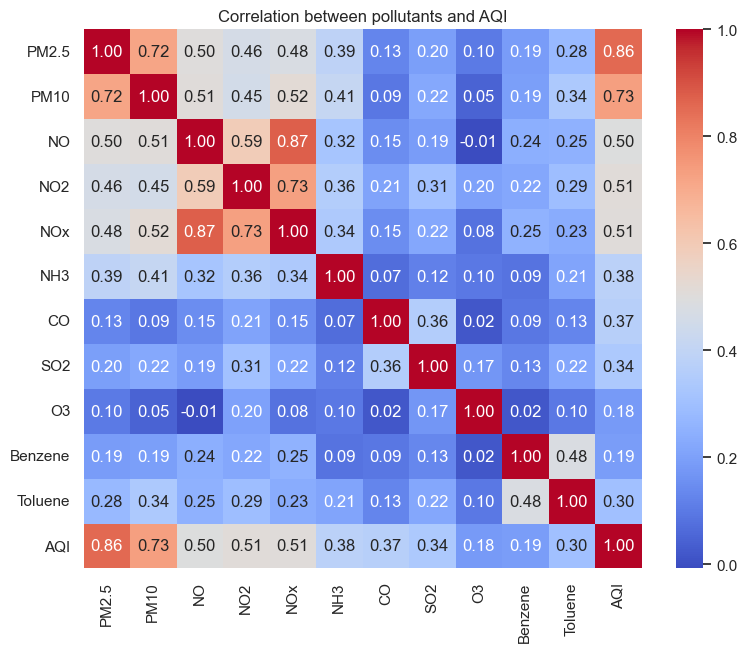

In [17]:
plt.figure(figsize=(9,7))
sns.heatmap(df[pollutants+['AQI']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation between pollutants and AQI')
plt.show()


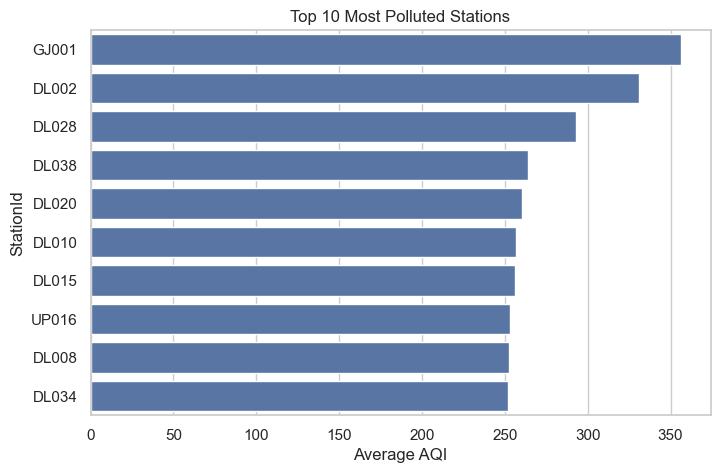

In [18]:
cnt = df.groupby('StationId').size()
valid = cnt[cnt >= 365].index
top = (df[df.StationId.isin(valid)]
       .groupby('StationId')['AQI'].mean()
       .sort_values(ascending=False).head(10))
plt.figure(figsize=(8,5))
sns.barplot(x=top.values, y=top.index, orient='h')
plt.xlabel('Average AQI'); plt.title('Top 10 Most Polluted Stations')
plt.show()


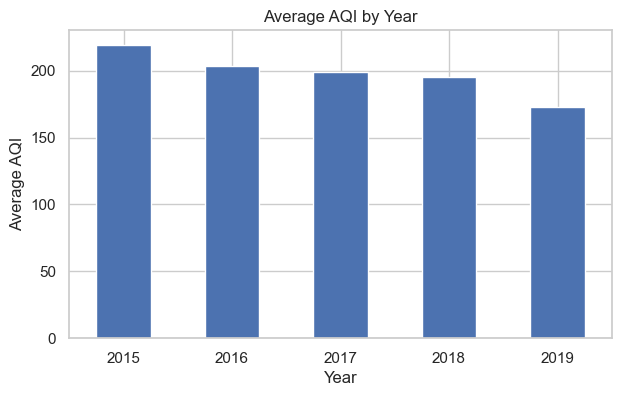

In [19]:
yr = df[df.Year < 2020].groupby('Year')['AQI'].mean()
plt.figure(figsize=(7,4))
yr.plot(kind='bar')
plt.ylabel('Average AQI'); plt.title('Average AQI by Year')
plt.xticks(rotation=0)
plt.show()
